# Does Medicaid volume affect curve shape and fit quality?

Registry topic `volume_vs_shape` ([README](README.md)). Gabrielle found that size drives the Medicaid gaps, and Christina found that 100 of 250 usable Bass fits are weak, most of them oncology. This notebook asks how much of that is **volume**:

1. **Volume in the pool:** how big are usable analogs in Medicaid, and does size differ by area and era?
2. **Fit quality vs volume:** does R² fall with volume?
3. **Volume or oncology?** Oncology is mostly small in Medicaid. Which one explains the weak fits?
4. **Noise or shape?** Shrink big, clean curves to small volumes with simulated counting noise and refit. Does noise alone reproduce what we see in small drugs?
5. **Shape vs volume:** do small drugs rise faster, peak earlier, fall more?
6. **Bass parameters vs volume:** among good fits, does volume shift p, q and m?

**Volume** = `peak_trx`, the highest Medicaid TRx in a quarter over Q0–Q20 (non-provisional). It's Medicaid-only, so it measures how much Medicaid uses a drug, not the drug's US size. **Usable** = the `checks.md` funnel (has Medicaid data, not `late_launch`, no generic in Q0–Q12, `enough_data`), the same definition as the other EDAs.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT))
from pipeline.bass import WEAK_R2, bass_cdf, fit, on_bound  # the pipeline's own Bass fit, so results match bass_fits.csv

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Team chart style (same tokens as launch_eda_christina). Categorical slots in fixed order: blue, orange, aqua.
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8f8e89"
INK, INK2 = "#0b0b0b", "#52514e"
RAMP = {"small": "#86b6ef", "mid": "#2a78d6", "large": "#104281"}  # ordinal: one hue, light -> dark = small -> large
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#ebeae6", "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 9,
})

In [2]:
analogs = pd.read_csv(PROCESSED / "analogs.csv", dtype=str, keep_default_na=False).set_index("analog_id")
features = pd.read_csv(PROCESSED / "analog_features.csv")
curves = pd.read_csv(PROCESSED / "launch_curves.csv")
fits = pd.read_csv(PROCESSED / "bass_fits.csv")

# Area as in launch_eda_christina: ATC level 1, with L split into oncology (L01-L02) and immunology (L03-L04)
ATC1 = {"A": "Alimentary & metabolism", "B": "Blood", "C": "Cardiovascular", "D": "Dermatology",
        "G": "GU & sex hormones", "H": "Systemic hormones", "J": "Anti-infectives", "M": "Musculoskeletal",
        "N": "Nervous system", "P": "Antiparasitic", "R": "Respiratory", "S": "Sensory organs", "V": "Various"}

def area(row):
    broad = row.class_broad if isinstance(row.class_broad, str) else ""
    if broad.startswith(("L01", "L02")):
        return "Oncology"
    if broad.startswith(("L03", "L04")):
        return "Immunology"
    code = row.therapeutic_area[:1] if isinstance(row.therapeutic_area, str) else ""
    return ATC1.get(code, "No ATC class")

features["area"] = features.apply(area, axis=1)
features["area3"] = features.area.where(features.area.isin(["Oncology", "Immunology"]), "Other")
features["approval_year"] = features.analog_id.map(analogs["approval date"]).str[:4].astype(int)
features["brand"] = features.analog_id.map(analogs["brand name"])

u = features[features.enough_data & ~features.late_launch & ~features.generic_entry_in_window].copy()
u = u.merge(fits, on="analog_id", how="left")

# Volume fifths, and three bands for charts: small = bottom two fifths, mid = middle two, large = top fifth
u["fifth"] = pd.qcut(u.peak_trx, 5, labels=["F1 smallest", "F2", "F3", "F4", "F5 largest"])
edges = u.groupby("fifth", observed=True).peak_trx.max()
u["band"] = pd.cut(u.peak_trx, [0, edges["F2"], edges["F4"], np.inf], labels=["small", "mid", "large"])
u["why_weak"] = np.select([u.fit_quality < WEAK_R2, u.weak_fit_flag], ["R2 < 0.9", "parameter on bound"], "good fit")

uc = curves[curves.analog_id.isin(u.analog_id) & ~curves.provisional].merge(u[["analog_id", "band", "area3"]], on="analog_id")
print(f"{len(u)} usable analogs, {u.p.notna().sum()} with a Bass fit; "
      f"bands: small <= {edges['F2']:,.0f} peak TRx/quarter < mid <= {edges['F4']:,.0f} < large")

250 usable analogs, 250 with a Bass fit; bands: small <= 766 peak TRx/quarter < mid <= 14,748 < large


## 1. Volume in the pool

Peak Medicaid TRx per quarter spans four orders of magnitude, so it's shown on a log scale. The bands used in the rest of the notebook are marked.

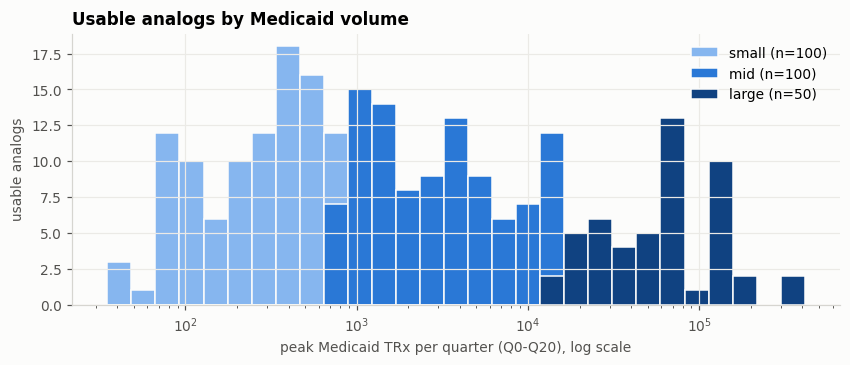

,analogs,peak_trx_min,peak_trx_median,peak_trx_max
fifth,,,,
F1 smallest,50,35.0,117.0,322.0
F2,50,323.0,502.5,766.0
F3,50,774.0,1263.5,2862.0
F4,50,2894.0,6328.5,14748.0
F5 largest,50,15060.0,63244.5,412798.0


In [3]:
fig, ax = plt.subplots(figsize=(9, 3.2))
bins = np.logspace(np.log10(u.peak_trx.min()), np.log10(u.peak_trx.max()), 30)
for band, color in RAMP.items():
    ax.hist(u.loc[u.band == band, "peak_trx"], bins=bins, color=color, edgecolor="#fcfcfb", linewidth=1,
            label=f"{band} (n={(u.band == band).sum()})")
ax.set_xscale("log")
ax.set_xlabel("peak Medicaid TRx per quarter (Q0-Q20), log scale")
ax.set_ylabel("usable analogs")
ax.set_title("Usable analogs by Medicaid volume")
ax.legend(loc="upper right")
plt.show()

u.groupby("fifth", observed=True).agg(analogs=("analog_id", "size"), peak_trx_min=("peak_trx", "min"),
                                      peak_trx_median=("peak_trx", "median"), peak_trx_max=("peak_trx", "max"))

Volume is not spread evenly across areas. If one area is mostly small, any volume effect will look like an area effect (and the reverse).

In [4]:
by_area = u.groupby("area").agg(analogs=("analog_id", "size"), median_peak_trx=("peak_trx", "median"),
                               pct_small=("band", lambda s: round(100 * (s == "small").mean())),
                               pct_large=("band", lambda s: round(100 * (s == "large").mean())))
by_area[by_area.analogs >= 8].sort_values("median_peak_trx")

,analogs,median_peak_trx,pct_small,pct_large
area,,,,
Oncology,62,396.5,69,0
Blood,15,1036.0,40,20
Immunology,28,1285.0,43,7
Alimentary & metabolism,34,1890.5,47,38
Cardiovascular,13,2439.0,8,15
Respiratory,8,6798.0,0,12
Anti-infectives,18,8571.0,28,39
Nervous system,41,13317.0,20,46


In [5]:
era = pd.cut(u.approval_year, [2009, 2013, 2017, 2021, 2025], labels=["2010-13", "2014-17", "2018-21", "2022-25"])
r = spearmanr(u.approval_year, u.peak_trx)
print(f"approval year vs peak TRx: Spearman rho = {r.statistic:.2f} (p = {r.pvalue:.2g})")
u.groupby(era, observed=True).agg(analogs=("analog_id", "size"), median_peak_trx=("peak_trx", "median"),
                                  pct_oncology=("area", lambda s: round(100 * (s == "Oncology").mean())))

approval year vs peak TRx: Spearman rho = -0.15 (p = 0.018)


,analogs,median_peak_trx,pct_oncology
approval_year,,,
2010-13,59,2272.0,27
2014-17,83,1296.0,23
2018-21,98,981.5,27
2022-25,10,988.5,10


## 2. Fit quality vs volume

Each dot is one usable analog's Bass fit (`bass_fits.csv`). The dashed line is the weak-fit threshold (R² 0.9). Values below 0 are clipped to 0 so the axis stays readable.

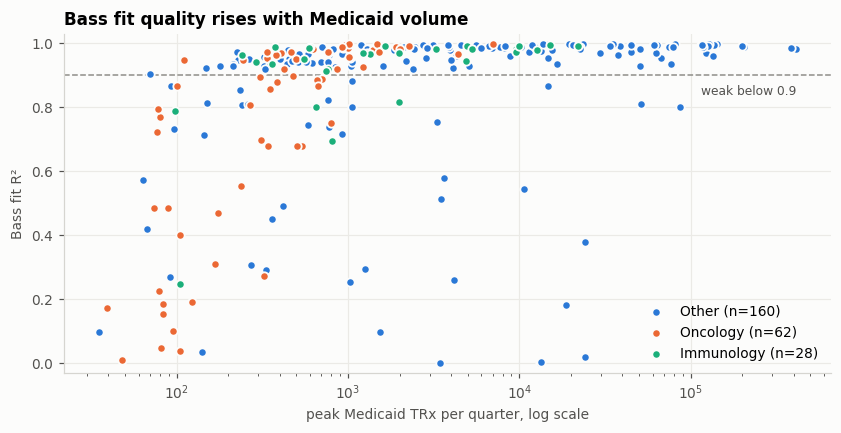

peak TRx vs R²: Spearman rho = 0.62 (p = 2e-27), n = 250


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
f_ = u.dropna(subset=["fit_quality"])
for name, color in [("Other", BLUE), ("Oncology", ORANGE), ("Immunology", AQUA)]:
    d = f_[f_.area3 == name]
    ax.scatter(d.peak_trx, d.fit_quality.clip(lower=0), s=30, color=color, edgecolor="#fcfcfb", lw=1.2,
               label=f"{name} (n={len(d)})", zorder=3)
ax.axhline(WEAK_R2, color=GRAY, lw=1, ls="--")
ax.text(f_.peak_trx.max(), WEAK_R2 - 0.03, "weak below 0.9", ha="right", va="top", fontsize=8, color=INK2)
ax.set_xscale("log")
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("peak Medicaid TRx per quarter, log scale")
ax.set_ylabel("Bass fit R²")
ax.set_title("Bass fit quality rises with Medicaid volume")
ax.legend(loc="lower right")
plt.show()

r = spearmanr(f_.peak_trx, f_.fit_quality)
print(f"peak TRx vs R²: Spearman rho = {r.statistic:.2f} (p = {r.pvalue:.2g}), n = {len(f_)}")

In [7]:
u.groupby("fifth", observed=True).agg(
    analogs=("analog_id", "size"), median_r2=("fit_quality", "median"),
    pct_weak=("weak_fit_flag", lambda s: round(100 * s.mean())),
    pct_r2_below_09=("why_weak", lambda s: round(100 * (s == "R2 < 0.9").mean())),
    pct_on_bound=("why_weak", lambda s: round(100 * (s == "parameter on bound").mean())),
    median_points=("n_points", "median"))

,analogs,median_r2,pct_weak,pct_r2_below_09,pct_on_bound,median_points
fifth,,,,,,
F1 smallest,50,0.72630,78,74,4,20.0
F2,50,0.93935,40,32,8,20.0
F3,50,0.96850,36,20,16,20.0
F4,50,0.98385,30,18,12,21.0
F5 largest,50,0.99015,16,10,6,21.0


Two kinds of weak fit behave differently: **R² < 0.9** is concentrated in small drugs, while **parameter on a bound** (mostly m at the 5.0 cap, curves still climbing at Q20) is spread across sizes. Volume explains the first kind, not the second.

## 3. Volume or oncology?

Christina's §4 found oncology is the weak-fit area (40 of 61 weak). Oncology is also the smallest area in Medicaid (§1). Split by both at once:

In [8]:
strat = u.groupby(["area3", "band"], observed=True).agg(
    analogs=("analog_id", "size"), median_r2=("fit_quality", "median"),
    pct_weak=("weak_fit_flag", lambda s: round(100 * s.mean())),
    pct_r2_below_09=("why_weak", lambda s: round(100 * (s == "R2 < 0.9").mean())))
strat

analogs  median_r2  pct_weak  pct_r2_below_09
area3      band                                                
Immunology small       12    0.93830        42               25
           mid         14    0.97635        29               14
           large        2    0.99380         0                0
Oncology   small       43    0.77110        77               74
           mid         19    0.98250        42                5
Other      small       45    0.92990        47               40
           mid         67    0.97650        31               24
           large       48    0.98975        17               10

In [9]:
rows = []
for name, d in u.dropna(subset=["fit_quality"]).groupby("area3"):
    r = spearmanr(d.peak_trx, d.fit_quality)
    rows.append({"area": name, "analogs": len(d), "rho_peak_vs_r2": round(r.statistic, 2), "p_value": f"{r.pvalue:.1g}"})
pd.DataFrame(rows).set_index("area")

,analogs,rho_peak_vs_r2,p_value
area,,,
Immunology,28,0.58,0.001
Oncology,62,0.81,2e-15
Other,160,0.55,3e-14


Within every area, bigger drugs fit better, and the relationship is strongest inside oncology. Mid-volume oncology fits about as well as mid-volume drugs elsewhere. The oncology problem is mostly a small-Medicaid-volume problem; there are no large oncology analogs to test the top band.

## 4. Noise or shape? A shrink-and-refit test

If small drugs fit badly only because their counts are noisy, then a big drug's curve, shrunk to small-drug volume, should fit just as badly. So for each **large** usable analog:

1. Take its real TRx curve and scale it so its peak is 100, 300 or 1,000 TRx a quarter (the shape is unchanged).
2. Add counting noise: patients ~ Poisson(TRx / 3), TRx = 3 × patients (about one fill a month). Real Medicaid noise is likely lumpier (new state contracts, stocking), so this is a lower bound on noise.
3. Suppress quarters under 11 TRx, as SDUD does. Keep only simulated curves that would pass the enough-data rule (no blank after Q2).
4. Recompute share of peak and refit with the pipeline's own `fit()`. 5 draws per analog per volume.

If the simulated weak-fit rates match the real ones at the same volume, noise is enough to explain the fit-quality gap. Comparing share of peak at Q5 tells us whether noise also explains the shape.

In [10]:
rng = np.random.default_rng(2026)
large = u[u.band == "large"].analog_id
sim = []
for aid in large:
    c = uc[uc.analog_id == aid].dropna(subset=["trx"]).sort_values("q_since_launch")
    shape, t_all = c.trx.to_numpy() / c.trx.max(), c.q_since_launch.to_numpy() + 1.0
    for target in [100, 300, 1000]:
        for draw in range(5):
            trx = 3.0 * rng.poisson(shape * target / 3)
            trx[trx < 11] = np.nan
            ok = ~np.isnan(trx)
            if (~ok[t_all > 3]).any():  # blank after Q2: the enough-data rule would drop it
                continue
            y, t = trx[ok] / trx[ok].max(), t_all[ok]
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = fit(t, y)
            sim.append({"analog_id": aid, "target_peak": target, "r2": res[3] if res else np.nan,
                        "share_q5": y[t == 6].mean() if (t == 6).any() else np.nan})
sim = pd.DataFrame(sim)

simulated = sim.groupby("target_peak").agg(curves=("r2", "size"), median_r2=("r2", "median"),
                                           pct_r2_below_09=("r2", lambda s: round(100 * (s < WEAK_R2).mean())),
                                           median_share_q5=("share_q5", "median"))
q5 = uc[uc.q_since_launch == 5].set_index("analog_id").share_of_peak
real = u.assign(share_q5=u.analog_id.map(q5)).groupby("fifth", observed=True).agg(
    median_peak_trx=("peak_trx", "median"), median_r2=("fit_quality", "median"),
    pct_r2_below_09=("why_weak", lambda s: round(100 * (s == "R2 < 0.9").mean())),
    median_share_q5=("share_q5", "median"))
print(f"Simulated from {len(large)} large analogs (real large-band median R² {u[u.band == 'large'].fit_quality.median():.3f}, "
      f"share at Q5 {q5[q5.index.isin(large)].median():.2f}):")
display(simulated.round(3))
print("Real usable analogs by volume fifth:")
real.round(3)

Simulated from 50 large analogs (real large-band median R² 0.990, share at Q5 0.27):


,curves,median_r2,pct_r2_below_09,median_share_q5
target_peak,,,,
100,120,0.735,94,0.362
300,208,0.934,33,0.290
1000,241,0.975,12,0.279


Real usable analogs by volume fifth:


,median_peak_trx,median_r2,pct_r2_below_09,median_share_q5
fifth,,,,
F1 smallest,117.0,0.726,74,0.533
F2,502.5,0.939,32,0.491
F3,1263.5,0.968,20,0.354
F4,6328.5,0.984,18,0.326
F5 largest,63244.5,0.990,10,0.272


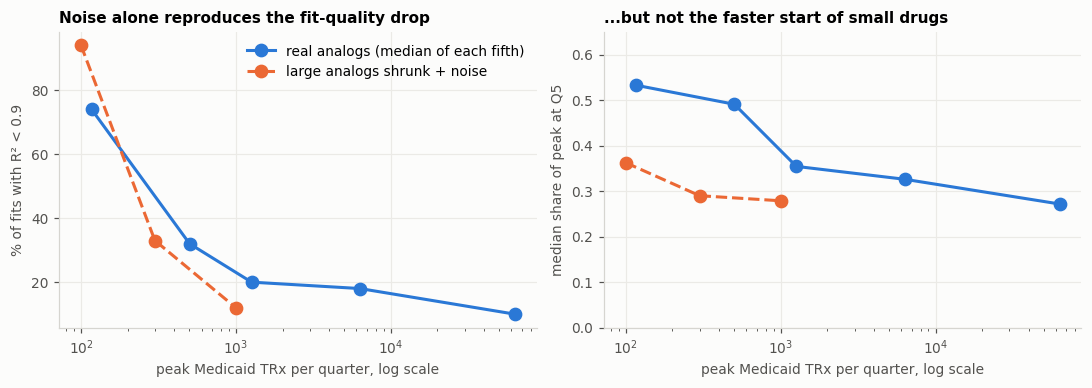

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, title, ylab in [
        (axes[0], "pct_r2_below_09", "Noise alone reproduces the fit-quality drop", "% of fits with R² < 0.9"),
        (axes[1], "median_share_q5", "...but not the faster start of small drugs", "median share of peak at Q5")]:
    ax.plot(real.median_peak_trx, real[col], color=BLUE, marker="o", ms=8, label="real analogs (median of each fifth)")
    ax.plot(simulated.index, simulated[col], color=ORANGE, marker="o", ms=8, ls="--", label="large analogs shrunk + noise")
    ax.set_xscale("log")
    ax.set_xlabel("peak Medicaid TRx per quarter, log scale")
    ax.set_ylabel(ylab)
    ax.set_title(title, fontsize=10)
axes[0].legend(loc="upper right")
axes[1].set_ylim(0, 0.65)
plt.tight_layout()
plt.show()

## 5. Shape vs volume

Median share of peak by quarter since launch for each volume band, with the interquartile range for small and large. Then the shape measures: quarters to 50% and 80% of peak, share at Q5, peak quarter, and **rise-and-fall** (last non-provisional quarter below 0.7 of peak).

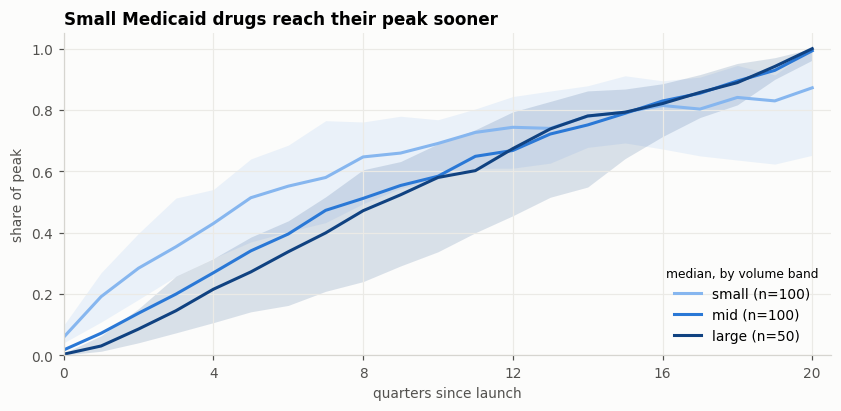

In [12]:
def band_stats(df):
    g = df.groupby("q_since_launch").share_of_peak
    return pd.DataFrame({"median": g.median(), "q25": g.quantile(0.25), "q75": g.quantile(0.75)})

fig, ax = plt.subplots(figsize=(9, 3.8))
for band, color in RAMP.items():
    d = uc[uc.band == band]
    b = band_stats(d)
    if band != "mid":
        ax.fill_between(b.index, b.q25, b.q75, color=color, alpha=0.15, lw=0)
    ax.plot(b.index, b["median"], color=color, label=f"{band} (n={d.analog_id.nunique()})")
ax.legend(loc="lower right", title="median, by volume band", title_fontsize=8)
ax.set_xlim(0, 20.5)
ax.set_ylim(0, 1.05)
ax.set_xticks(range(0, 21, 4))
ax.set_xlabel("quarters since launch")
ax.set_ylabel("share of peak")
ax.set_title("Small Medicaid drugs reach their peak sooner")
plt.show()

In [13]:
def first_q(c, level):
    hit = c[c.share_of_peak >= level]
    return hit.q_since_launch.min() if len(hit) else np.nan

shape = uc.sort_values("q_since_launch").groupby("analog_id").apply(lambda c: pd.Series({
    "q50": first_q(c, 0.5), "q80": first_q(c, 0.8),
    "share_q5": c.loc[c.q_since_launch == 5, "share_of_peak"].mean(),
    "last_share": c.share_of_peak.dropna().iloc[-1]}), include_groups=False)
u = u.merge(shape, left_on="analog_id", right_index=True, how="left")
u["rise_and_fall"] = u.last_share < 0.7

u.groupby("band", observed=True).agg(
    analogs=("analog_id", "size"), q50=("q50", "median"), q80=("q80", "median"), share_q5=("share_q5", "median"),
    peak_q=("peak_q", "median"), pct_peak_at_last=("peak_at_last_quarter", lambda s: round(100 * s.mean())),
    pct_rise_and_fall=("rise_and_fall", lambda s: round(100 * s.mean())))

,analogs,q50,q80,share_q5,peak_q,pct_peak_at_last,pct_rise_and_fall
band,,,,,,,
small,100,5.0,12.0,0.51370,16.0,35,27
mid,100,8.0,14.0,0.34030,19.0,54,14
large,50,9.0,14.5,0.27165,19.0,60,8


Is the faster start a volume effect or an area effect? Share of peak at Q5 within each area:

In [14]:
within = u.pivot_table(index="area3", columns="band", values="share_q5", aggfunc="median", observed=True).round(2)
within["n (small/mid/large)"] = u.groupby("area3").band.apply(
    lambda s: "/".join(str((s == b).sum()) for b in ["small", "mid", "large"]))
rows = []
for name, d in u.groupby("area3"):
    r = spearmanr(d.peak_trx, d.share_q5, nan_policy="omit")
    rows.append((name, round(r.statistic, 2), f"{r.pvalue:.1g}"))
within.join(pd.DataFrame(rows, columns=["area3", "rho_peak_vs_q5", "p_value"]).set_index("area3"))

,small,mid,large,n (small/mid/large),rho_peak_vs_q5,p_value
area3,,,,,,
Immunology,0.55,0.27,0.13,12/14/2,-0.61,0.0005
Oncology,0.51,0.20,NaN,43/19/0,-0.57,1e-06
Other,0.50,0.40,0.28,45/67/48,-0.36,3e-06


Which small drugs rise and fall? The 15 smallest usable analogs, with their fits:

In [15]:
u.nsmallest(15, "peak_trx")[["analog_id", "area", "peak_trx", "peak_q", "last_share", "fit_quality", "why_weak"]
                          ].round(3).set_index("analog_id")

,area,peak_trx,peak_q,last_share,fit_quality,why_weak
analog_id,,,,,,
carbaglu_oral,Alimentary & metabolism,35.0,20.0,1.000,0.096,R2 < 0.9
inrebic_oral,Oncology,39.0,5.0,0.513,0.172,R2 < 0.9
caprelsa_oral,Oncology,48.0,15.0,0.417,0.010,R2 < 0.9
amvuttra_sc,Nervous system,64.0,12.0,1.000,0.574,R2 < 0.9
xadago_oral,Nervous system,67.0,10.0,0.672,0.420,R2 < 0.9
cerdelga_oral,Alimentary & metabolism,70.0,16.0,0.857,0.906,good fit
vitrakvi_oral,Oncology,74.0,18.0,0.851,0.486,R2 < 0.9
idhifa_oral,Oncology,77.0,15.0,0.831,0.722,R2 < 0.9
vonjo_oral,Oncology,78.0,13.0,1.000,0.794,R2 < 0.9


## 6. Bass parameters vs volume

The forecaster will take p and q from analogs. Among **good fits only** (not weak), does volume still shift the parameters? If it does, an analog set that mixes sizes mixes shapes.

In [16]:
good = u[u.why_weak == "good fit"]
params = good.groupby("band", observed=True).agg(good_fits=("p", "size"), p_median=("p", "median"),
                                                 q_median=("q", "median"), m_median=("m", "median"))
rows = []
for col in ["p", "q", "m"]:
    r = spearmanr(good.peak_trx, good[col])
    rows.append({"param": col, "rho_vs_peak_trx": round(r.statistic, 2), "p_value": f"{r.pvalue:.1g}"})
display(params.round(3))
pd.DataFrame(rows).set_index("param")

,good_fits,p_median,q_median,m_median
band,,,,
small,41,0.058,0.093,1.056
mid,67,0.025,0.208,1.059
large,42,0.019,0.189,1.166


,rho_vs_peak_trx,p_value
param,,
p,-0.35,1e-05
q,0.25,0.002
m,0.09,0.3


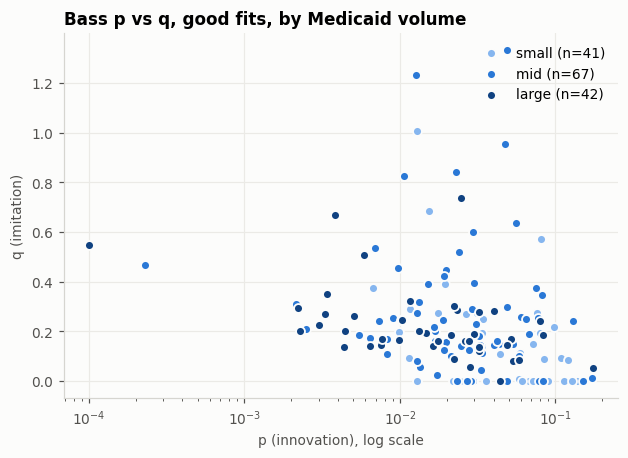

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4.3))
for band, color in RAMP.items():
    d = good[good.band == band]
    ax.scatter(d.p, d.q, s=34, color=color, edgecolor="#fcfcfb", lw=1.2, label=f"{band} (n={len(d)})", zorder=3)
ax.set_xscale("log")
ax.set_xlabel("p (innovation), log scale")
ax.set_ylabel("q (imitation)")
ax.set_title("Bass p vs q, good fits, by Medicaid volume")
ax.legend(loc="upper right")
plt.show()

## Takeaways

*From the committed tables (`main` at `2dec2a2`). Numbers are typed in, so update them when the tables are rebuilt.*

**Volume in the pool**
- Peak Medicaid TRx per quarter spans 35 to 413k; the median usable analog peaks at about 1,260. Bands: small ≤ 766 (100 analogs), mid ≤ 14,748 (100), large (50).
- **Oncology is the smallest area in Medicaid:** median peak 386, 70% small, no large analogs. Nervous system is the largest (median 13,317, 46% large). Volume falls slightly with approval year (ρ = −0.15).

**Fit quality is mostly a volume effect**
- Peak TRx vs Bass R²: ρ = 0.62. 74% of the smallest fifth (peak ≤ 322) have R² < 0.9, falling to 10% in the largest fifth.
- **Within every area bigger fits better**, most strongly in oncology (ρ = 0.80). **Mid-volume oncology has R² < 0.9 in only 6% of fits (1 of 18)**, vs 74% of small oncology. So the oncology weak-fit finding in `launch_eda` §4 is largely oncology being small in Medicaid, not a shape Bass can't fit.
- The other kind of weak fit, a **parameter on a bound** (m at the cap, still climbing), is not concentrated in small drugs (4–16% in every fifth).

**Noise explains the bad fits, not the shape**
- Large analogs shrunk to a peak of 100 / 300 / 1,000 TRx with counting noise have R² < 0.9 in 94% / 33% / 12% of fits. Real analogs at those volumes: 74% / 32% / 20%. **Counting noise alone is enough to produce the fit-quality gradient.** Below a peak of about 300 TRx a quarter, R² mostly measures noise.
- But noise doesn't make curves front-loaded: shrunk curves reach 0.29–0.36 of peak at Q5; real small drugs reach 0.49–0.53.

**Small drugs really do have a different shape**
- Small drugs reach 50% of peak at Q5 (median), vs Q8 mid and Q9 large; 0.51 of peak at Q5 vs 0.27 for large. 27% of small drugs rise and fall (end below 0.7 of peak) vs 8% of large.
- It holds within area: share at Q5 falls with volume in oncology (ρ = −0.56), immunology (−0.61) and other areas (−0.35).
- **Among good fits only**, small drugs have higher p (0.058 vs 0.019 large) and lower q (0.09 vs 0.19). Volume shifts the Bass parameters, not just their noise.
- Likely reason (not tested here): small Medicaid drugs are rare-disease and biomarker-selected cancer drugs with a small, known patient pool that is treated quickly.

**What this means for the tool**
1. **Don't trust R² alone for small analogs.** Below about 300–500 peak TRx a quarter, a low R² is expected from noise even when the underlying shape is fine. Flag low-volume analogs (or down-weight them) rather than reading their fits as a shape signal.
2. **Use volume as a similarity feature** in `analog_recommendations`: a small-population target should be matched to small analogs (fast start, earlier peak), a broad one to large analogs. Mixing sizes blends two shapes.
3. **Revisit "oncology is the problem area"**: the evidence points to Medicaid volume; mid-volume oncology fits fine. Christina's suggestion to try another curve form for oncology is still worth it for the rise-and-fall cases.

**Open checks**
- Volume here is Medicaid-only. Oncology is Medicare-heavy, so a Medicaid-small cancer drug may be large nationally. A Part D cross-check (`launch_eda` and data_sources.md: cross-check only) would show whether "small" means small market or just small in Medicaid.
- The noise model (Poisson patients × 3 fills) is a lower bound; real quarter-to-quarter swings are lumpier, so the true noise threshold may be higher than 300.
- Peak TRx is partly undercounted where some rows are suppressed (`launch_eda`: 94% of usable analogs have a suppressed row somewhere); this biases small drugs most.